# Rydberg Blockade Lab

Python companion to the AMO Toolkit page [Rydberg Blockade Lab](https://amotoolkit.com/pages/rydberg-calculator.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/rydberg-calculator.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Quantum defects and scaling laws
Effective principal number $n^* = n - \delta_0 - \delta_2/(n-\delta_0)^2$; binding energy $R_y/n^{*2}$; mean orbital radius ≈ 1.5 n*² a₀; radiative lifetime τ₀ n*³; van der Waals $C_6 \propto n^{*11}$ anchored at one reference state per series; blockade radius $R_b = (C_6/\hbar\Omega)^{1/6}$.

**Read with care.** These are the page's scaling estimates, good to tens of percent for nS states. The lifetime is radiative only (0 K): blackbody radiation at 300 K shortens it substantially at large n. P and D states have anisotropic, sometimes near-resonant interactions that a single C₆ cannot describe. For numbers you will build on, use the [ARC calculator](https://github.com/nikolasibalic/ARC-Alkali-Rydberg-Calculator) (an optional cell below uses it if installed).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Ry_eV, a0_nm = 13.605693, 0.052918
# (species, series): (δ0, δ2, τ0 [ns], C6 at reference [GHz·µm⁶], reference n*)
DATA = {
    ("Rb", "nS"): (3.1311804, 0.1784, 1.43, 15, 46.87),
    ("Rb", "nP1"): (2.6548849, 0.2900, 2.76, 280, 47.35),
    ("Rb", "nP3"): (2.6416737, 0.2950, 2.76, 400, 47.36),
    ("Rb", "nD3"): (1.34809171, -0.60286, 3.80, 200, 48.65),
    ("Rb", "nD5"): (1.34646572, -0.59600, 3.80, 250, 48.65),
    ("Cs", "nS"): (4.0493532, 0.2391, 1.80, 25, 45.95),
    ("Cs", "nP1"): (3.5914767, 0.3500, 3.50, 450, 46.41),
    ("Cs", "nP3"): (3.5590268, 0.3740, 3.50, 650, 46.44),
    ("Cs", "nD3"): (2.4754562, 0.0090, 4.50, 350, 47.52),
    ("Cs", "nD5"): (2.4663544, 0.0120, 4.50, 400, 47.53),
    ("Li", "nS"): (0.3995101, 0.0290, 0.35, 2, 49.60),
    ("Li", "nP1"): (0.0471780, -0.0240, 0.80, 60, 49.95),
    ("Li", "nP3"): (0.0471780, -0.0240, 0.80, 60, 49.95),
    ("Li", "nD3"): (0.0021290, -0.0120, 1.50, 30, 49.998),
    ("Li", "nD5"): (0.0021290, -0.0120, 1.50, 30, 49.998),
    ("Na", "nS"): (1.347969, 0.06137, 0.70, 8, 48.65),
    ("Na", "nP1"): (0.855424, 0.11193, 1.50, 180, 49.14),
    ("Na", "nP3"): (0.854566, 0.11296, 1.50, 180, 49.15),
    ("Na", "nD3"): (0.014867, -0.0410, 2.80, 100, 49.985),
    ("Na", "nD5"): (0.014656, -0.0400, 2.80, 100, 49.985),
    ("K", "nS"): (2.1801985, 0.1300, 0.90, 10, 47.82),
    ("K", "nP1"): (1.713892, 0.2330, 2.00, 220, 48.29),
    ("K", "nP3"): (1.720168, 0.1930, 2.00, 220, 48.28),
    ("K", "nD3"): (0.276970, -0.0100, 3.20, 130, 49.72),
    ("K", "nD5"): (0.277000, -0.0100, 3.20, 130, 49.72),
}

def rydberg(species="Rb", series="nS", n=50, Omega_MHz=1.0, r_um=5.0):
    d0, d2, tau0, C6ref, nref = DATA[(species, series)]
    ns = n - d0 - d2 / (n - d0) ** 2
    C6 = C6ref * (ns / nref) ** 11
    Rb = (abs(C6) * 1000 / Omega_MHz) ** (1 / 6)
    return dict(n_star=ns, E_bind_eV=Ry_eV / ns**2, E_bind_cm=Ry_eV / ns**2 * 8065.54, r_a0=1.5 * ns**2,
                r_nm=1.5 * ns**2 * a0_nm, tau_us=tau0 * 1e-3 * ns**3, C6_GHz_um6=C6, R_b_um=Rb,
                U_MHz=abs(C6) / r_um**6 * 1000, blockaded=r_um < Rb)

r = rydberg()     # page defaults: Rb 50S, Ω/2π = 1 MHz, r = 5 µm
for k, v in r.items():
    print(f"{k:>12} = {v:.4g}" if not isinstance(v, bool) else f"{k:>12} = {v}")

      n_star = 46.87
   E_bind_eV = 0.006194
   E_bind_cm = 49.96
        r_a0 = 3295
        r_nm = 174.4
      tau_us = 147.2
  C6_GHz_um6 = 15
      R_b_um = 4.966
       U_MHz = 0.9597
   blockaded = False

## 2. Blockade radius against n
Because $C_6 \propto n^{11}$, $R_b \propto n^{11/6}$ at fixed Ω, while the lifetime grows only as $n^3$.

R_b(70)/R_b(50) = 1.92; (n*70/n*50)^(11/6) = 1.92

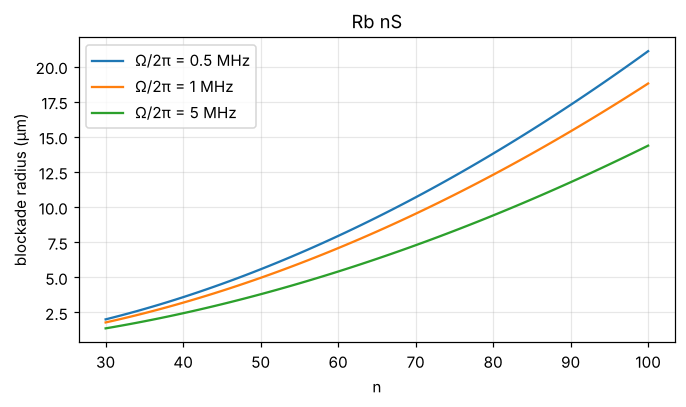

In [2]:
ns = np.arange(30, 101)
for Om in (0.5, 1, 5):
    plt.plot(ns, [rydberg(n=n, Omega_MHz=Om)["R_b_um"] for n in ns], label=f"Ω/2π = {Om} MHz")
plt.xlabel("n"); plt.ylabel("blockade radius (µm)"); plt.legend(); plt.title("Rb nS")
a, b = rydberg(n=50), rydberg(n=70)
print(f"R_b(70)/R_b(50) = {b['R_b_um']/a['R_b_um']:.2f}; (n*70/n*50)^(11/6) = {(b['n_star']/a['n_star'])**(11/6):.2f}")

## 3. Two atoms under blockade
Two atoms driven together from |gg⟩ with interaction U in the |rr⟩ state. With U ≫ Ω the pair oscillates between |gg⟩ and the symmetric single excitation at √2 Ω and |rr⟩ stays empty.

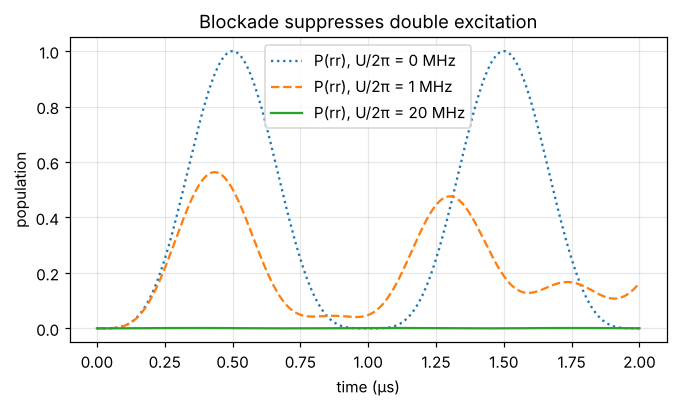

In [3]:
def pair(Omega, U, t):
    """Populations of |gg>, |W> (one excitation) and |rr> for resonant drive, rates in rad/µs."""
    H = np.array([[0, np.sqrt(2) * Omega / 2, 0], [np.sqrt(2) * Omega / 2, 0, np.sqrt(2) * Omega / 2], [0, np.sqrt(2) * Omega / 2, U]])
    w, V = np.linalg.eigh(H)
    psi0 = np.array([1, 0, 0.0])
    amps = V @ (np.exp(-1j * np.outer(w, t)) * (V.T @ psi0)[:, None])
    return np.abs(amps) ** 2

t = np.linspace(0, 2, 500)          # µs
Om = 2 * np.pi * 1.0
for U_MHz, ls in ((0, ":"), (1, "--"), (20, "-")):
    P = pair(Om, 2 * np.pi * U_MHz, t)
    plt.plot(t, P[2], ls, label=f"P(rr), U/2π = {U_MHz} MHz")
plt.xlabel("time (µs)"); plt.ylabel("population"); plt.legend(); plt.title("Blockade suppresses double excitation")

In [4]:
try:
    import arc                                  # optional: pip install ARC-Alkali-Rydberg-Calculator
    atom = arc.Rubidium87()
    print("ARC radiative + BBR lifetime of 50S at 300 K:", atom.getStateLifetime(50, 0, 0.5, temperature=300) * 1e6, "µs")
except Exception as err:                    # not installed, or a different ARC version
    print(f"ARC not available ({type(err).__name__}); skip. Install it for accurate C6, lifetimes and pair potentials.")

ARC not available (ModuleNotFoundError); skip. Install it for accurate C6, lifetimes and pair potentials.

## 4. Check against the page

In [5]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

DECIMALS = dict(n_star=4, E_bind_eV=4, E_bind_cm=1, r_a0=0, r_nm=1, tau_us=1, C6_GHz_um6=1, R_b_um=2, U_MHz=1)
page = dict(n_star=46.8687, E_bind_eV=0.0062, E_bind_cm=50.0, r_a0=3295, r_nm=174.4, tau_us=147.2, C6_GHz_um6=15.0, R_b_um=4.97, U_MHz=1.0)
check(r, page)

      n_star: notebook 46.87        page 46.8687    OK
   E_bind_eV: notebook 0.006194     page 0.0062     OK
   E_bind_cm: notebook 49.96        page 50         OK
        r_a0: notebook 3295         page 3295       OK
        r_nm: notebook 174.4        page 174.4      OK
      tau_us: notebook 147.2        page 147.2      OK
  C6_GHz_um6: notebook 15           page 15         OK
      R_b_um: notebook 4.966        page 4.97       OK
       U_MHz: notebook 0.9597       page 1          OK
All values match the page.